<a href="https://colab.research.google.com/github/JFSS20000/SEMINARIO/blob/main/2026_Seminario_Algoritmos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algoritmos de optimización - Seminario<br>
Nombre y Apellidos: JOSE FERNANDO SARMIENTO SARMIENTO  <br>
Url: https://github.com/JFSS20000/SEMINARIO/blob/main/2026_Seminario_Algoritmos.ipynb<br>

Problema:
> 1. Sesiones de doblaje <br>

#### Descripción del problema:

Se precisa coordinar el doblaje de una película. Los actores del doblaje deben coincidir en las tomas en las que sus personajes aparecen juntos en las diferentes tomas. Los actores de doblaje cobran todos la misma cantidad por cada día que deben desplazarse hasta el estudio de grabación independientemente del número de tomas que se graben. No es posible grabar más de 6 tomas por día. El objetivo es planificar las sesiones por día de manera que el gasto por los servicios de los actores de doblaje sea el menor posible. Los datos son:

  Número de actores: 10

  Número de tomas: 30

  Actores/Tomas: https://bit.ly/36D8IuK

  * 1 = indica que el actor participa en la toma
  * 0 = en caso contrario



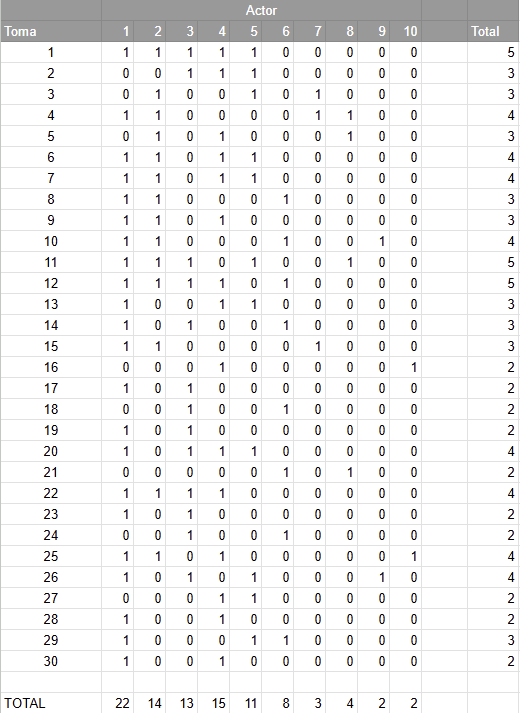

(*)¿Cuantas posibilidades hay sin tener en cuenta las restricciones?<br>



¿Cuantas posibilidades hay teniendo en cuenta todas las restricciones?




**Respuesta**

Cantidad de posibilidades sin tener en cuenta las restricciones:

1. Si se quiere repartir las 30 tomas en 5 días sin ninguna restricción, el total de posibilidades sería las combinaciones:
   $$\text{Posibilidades} = 5^{30} \approx 9,31 \times 10^{20}$$

   es decir, más de 931 mil trillones de posibilidades.



In [10]:
import math
print(f"{5**30:e}")

9.313226e+20


2. Si se elimina el máximo de 6 tomas por día, se podría asignar las 30 tomas en un solo día, el total de posibilidades sería las permutaciones:
    $$\text{Posibilidades} = 30! \approx 2,6525 \times 10^{32}$$

    es decir, más de 265 mil trillones de posibilidades.


In [11]:
import math
print(f"{math.factorial(30):e}")

2.652529e+32


<br>Cantidad de posibilidades tomando en cuenta todas las restricciones:
1. ≤ 6 tomas/día
2. Cada toma exactamente 1 vez
3. Actores compatibles (solo tomas donde aparecen juntos)
4. Realizar el total de 30 tomas

Para realizar 30 tomas con un máximo de 6 tomas/día, el número mínimo de jornadas sería 5 días ($30 / 6 = 5$). Por lo tanto, las soluciones distribuyen las tomas en **5 bloques de 6 tomas**.

El número de combinaciones válidas se calcula mediante el **coeficiente multinomial**:

**A. Días etiquetados (Día 1, Día 2, ..., Día 5)**

Si consideramos que el orden de los días importa (p. ej., asignar el bloque al Lunes vs. al Martes):

$$ \text{Posibilidades} = \frac{30!}{(6!)^5} \approx 1,37 \times 10^{18} \quad \text{(1,37 trillones)} $$


In [12]:
import math
posibilidades_con_restriccion = math.factorial(30) / (math.factorial(6)**5)
print(f"{posibilidades_con_restriccion:e}")

1.370874e+18



**B. Días equivalentes (Agrupaciones puras)**

Si el orden cronológico de los días no altera el coste total (intercambiar el Día 1 con el Día 2 no cambia el gasto acumulado):

$$ \text{Posibilidades} = \frac{30!}{(6!)^5 \cdot 5!} \approx 1,14 \times 10^{16} \quad \text{(11,4 mil billones)} $$


In [13]:
import math
posibilidades_con_restriccion_2 = math.factorial(30) / ((math.factorial(6)**5)*math.factorial(5))
print(f"{posibilidades_con_restriccion_2:e}")

1.142395e+16




---



Modelo para el espacio de soluciones<br>
(*) ¿Cual es la estructura de datos que mejor se adapta al problema? Argumentalo.(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, argumentalo)


Respuesta

**A. Estructura de Datos para Representar el Problema (Datos de Entrada)**

  1. **Matriz de Incidencia / Presencia Actor-Toma ($M$)**
      * **Estructura:** Matriz binaria 2D de NumPy de enteros 0/1).
      * **Dimensiones:** $30 \times 10$ ($N=30$ tomas, $A=10$ actores).
      * **Definición:**
  $$M[s, a] = \begin{cases} 1 & \text{si el actor } a \text{ participa en la toma } s \\ 0 & \text{no participa} \end{cases}$$
      * **Justificación:** Ocupa solo 300 bytes en memoria. Permite realizar operaciones vectorizadas (filtros de presencia por día mediante la operación `OR`) a velocidad de código nativo C en NumPy.

In [14]:
import pandas as pd
import numpy as np

# Usar el archivo CSV de los datos (modificado para exportar como CSV real)
url = 'https://docs.google.com/spreadsheets/d/1Ipn6IrbQP4ax8zOnivdBIw2lN0JISkJG4fXndYd27U0/export?format=csv'
df = pd.read_csv(url)

# Se crea un nuevo data frame únicamente con el valor de los datos
# - quitando la primera y las dos últimas filas
# - quitando la primera y las dos últimas columnas
datos_np = df.iloc[1:-2, 1:-2].to_numpy()
datos_np = np.nan_to_num(datos_np, nan=0).astype(int)

NUM_TOMAS = datos_np.shape[0]     # El número de tomas son las filas del array
NUM_ACTORES = datos_np.shape[1]   # El número de actores son las columnas del array

print(f"Tomas: {NUM_TOMAS}")
print(f"Actores: {NUM_ACTORES}")
print("--")
print(f"Datos M[{NUM_TOMAS}][{NUM_ACTORES}]: ")
#print(datos_np)

# Crear el DataFrame para visualización
filas = [f"T-{i+1}" for i in range(NUM_TOMAS)]
columnas = [f"A{j+1}" for j in range(NUM_ACTORES)]

df_limpio = pd.DataFrame(datos_np, index=filas, columns=columnas)
print(df_limpio)



Tomas: 30
Actores: 10
--
Datos M[30][10]: 
      A1  A2  A3  A4  A5  A6  A7  A8  A9  A10
T-1    1   1   1   1   1   0   0   0   0    0
T-2    0   0   1   1   1   0   0   0   0    0
T-3    0   1   0   0   1   0   1   0   0    0
T-4    1   1   0   0   0   0   1   1   0    0
T-5    0   1   0   1   0   0   0   1   0    0
T-6    1   1   0   1   1   0   0   0   0    0
T-7    1   1   0   1   1   0   0   0   0    0
T-8    1   1   0   0   0   1   0   0   0    0
T-9    1   1   0   1   0   0   0   0   0    0
T-10   1   1   0   0   0   1   0   0   1    0
T-11   1   1   1   0   1   0   0   1   0    0
T-12   1   1   1   1   0   1   0   0   0    0
T-13   1   0   0   1   1   0   0   0   0    0
T-14   1   0   1   0   0   1   0   0   0    0
T-15   1   1   0   0   0   0   1   0   0    0
T-16   0   0   0   1   0   0   0   0   0    1
T-17   1   0   1   0   0   0   0   0   0    0
T-18   0   0   1   0   0   1   0   0   0    0
T-19   1   0   1   0   0   0   0   0   0    0
T-20   1   0   1   1   1   0   0   0 

  2. **Contenedor de Parámetros y Restricciones (Objeto/Diccionario)**
      * **Estructura:** Diccionario o `dataclass` de Python.
      * **Propiedades:**
        * `NUM_TOMAS` $= 30$
        * `NUM_ACTORES` $= 10$
        * `MAX_TOMAS_POR_DIA` $= 6$
        * `MIN_DIAS` $= \lceil 30 / 6 \rceil = 5$

In [15]:
import math

# Definición del diccionario de parámetros y restricciones

MAX_TOMAS_POR_DIA = 6

parametros_restricciones = {
    "NUM_TOMAS": NUM_TOMAS,
    "NUM_ACTORES": NUM_ACTORES,
    "MAX_TOMAS_POR_DIA": MAX_TOMAS_POR_DIA,
    "MIN_DIAS": math.ceil(NUM_TOMAS / MAX_TOMAS_POR_DIA),
}

# Ejemplo de acceso:
print(f"Número de tomas: {parametros_restricciones['NUM_TOMAS']}")
print(f"Mínimo de días requeridos: {parametros_restricciones['MIN_DIAS']}")

Número de tomas: 30
Mínimo de días requeridos: 5


<br>**B. Estructura de Datos para el Espacio de Búsqueda (Solución Candidata)**

Representa cada estado o punto dentro del espacio de búsqueda $\mathcal{S}$ que un algoritmo de optimización genera y evalúa.

  1. **Codificación Primaria**: Vector de Asignación Directa (Array 1D)
      * **Estructura:** Arreglo unidimensional de enteros (`numpy.ndarray` de tamaño $N=30$).
      * **Definición:**
  $$\text{Vector } V = [d_0, d_1, d_2, \dots, d_{29}], \quad \text{donde } d_s \in \{0, 1, 2, 3, 4\}$$
        * El **índice** $s$ del arreglo representa la **Toma $s$**.
        * El **valor** $V[s]$ representa el **Día de grabación asignado** ($0$ a $4$).
<br>

  2. **Argumentación Técnica**:
        * Garantía Estructural de **Unicidad**:

            Al usar un vector de tamaño 30 donde el índice es la toma, aseguramos que todas las tomas sean asignadas y que no pueda repetirse en dos días distintos. La restricción de "cada toma exactamente 1 vez" queda satisfecha por el propio tipo de dato

        * **Eficiencia Computacional** $O(N)$:
          
            Se reduce la complejidad de $O(N \cdot D)$ (matriz) a $O(N)$ (vector 1D), con $N=30$ datos.

        * **Optimizado para Metaheurísticas**:

            Facilita operadores de mutación rápidos, simplemente cambiando un entero en el arreglo, sin romper la estructura de la solución.


    ***Ejemplo de solución:***
    

In [16]:
# Muestra un reparto de 30 tomas organizadas en 5 días (0 a 4)
solucion_candidata = np.array([
    0, 0, 0, 0, 0, 0,  # Tomas 0..5   -> Día 0 (6 tomas)
    1, 1, 1, 1, 1, 1,  # Tomas 6..11  -> Día 1 (6 tomas)
    2, 2, 2, 2, 2, 2,  # Tomas 12..17 -> Día 2 (6 tomas)
    3, 3, 3, 3, 3, 3,  # Tomas 18..23 -> Día 3 (6 tomas)
    4, 4, 4, 4, 4, 4   # Tomas 24..29 -> Día 4 (6 tomas)
])

print(solucion_candidata)

[0 0 0 0 0 0 1 1 1 1 1 1 2 2 2 2 2 2 3 3 3 3 3 3 4 4 4 4 4 4]




---



Según el modelo para el espacio de soluciones<br>
(*)¿Cual es la función objetivo?

(*)¿Es un problema de maximización o minimización?

Respuesta

**A. Función objetivo**

Con el problema expuesto de reducir el valor a pagar a los actores, la función objetivo es la suma total de jornadas diarias que deben cobrar los actores durante los días de grabación.

El problema nos dice que todos los actores cobran la misma tarifa por cada dia que acuden al estudio (sin importar cuantas tomas graban en el día), la función mide cuantos actores "se activan" en cada jornada de grabación.

  1. **Expresión Matemática**
      * Dado el vector de solución $V$ (donde $V[s] = d$ indica el día $d$ asignado a la toma $s$) y la matriz de incidencia $M_{s,a}$ ($1$ si el actor $a$ actúa en la toma $s$, $0$ si no lo hace):
      
      * Indicador de presencia del actor $a$ en el día $d$ ($y_{a,d}$):$$y_{a,d} = \max_{s \mid V[s] = d} (M_{s,a}) \in \{0, 1\}$$(Vale 1 si el actor $a$ participa en al menos una toma programada para el día $d$, y 0 si no tiene ninguna toma ese día).

      * Función Objetivo $f(V)$:
      
      $$f(V) = \sum_{d=0}^{4} \sum_{a=0}^{9} y_{a,d}$$
      
      * En Python (NumPy), se calcula identificando para cada día qué actores están presentes usando una operación lógica $\text{OR}$ a lo largo de las tomas de ese día, y sumando el total.
<br>

**B. Tipo de problema**

    Es un problema de "MINIMIZACIÓN"

   * **Razón**: El objetivo del problema es reducir al mínimo posible el coste financiero total del rodaje.



---



Diseña un algoritmo para resolver el problema por fuerza bruta

Respuesta

In [17]:
import numpy as np
import time

def funcion_coste(solucion, matriz_M, n_dias=5):
    coste_total = 0
    for d in range(n_dias):
        tomas_del_dia = np.where(solucion == d)[0]
        if len(tomas_del_dia) > 0:
            # Si el actor actúa en al menos una toma del día, acude al estudio
            actores_presentes = np.any(matriz_M[tomas_del_dia], axis=0)
            coste_total += np.sum(actores_presentes)
    return coste_total

# ALGORITMO DE FUERZA BRUTA CON BACKTRACKING
def resolver_fuerza_bruta(matriz_M, max_tomas_por_dia=6, n_dias=5, limite_evaluaciones=None):
    n_tomas, n_actores = matriz_M.shape

    solucion_actual = np.full(n_tomas, -1, dtype=int)
    conteo_dias = [0] * n_dias

    mejor_coste = float('inf')
    mejor_solucion = None
    evaluaciones = 0
    tiempo_inicio = time.time()

    def backtracking(toma_idx, max_dia_usado):
        nonlocal mejor_coste, mejor_solucion, evaluaciones

        # Detener si se alcanza el límite de prueba configurado
        if limite_evaluaciones and evaluaciones >= limite_evaluaciones:
            return

        # CASO BASE: 30 tomas
        if toma_idx == n_tomas:
            evaluaciones += 1
            coste_actual = funcion_coste(solucion_actual, matriz_M, n_dias)

            if coste_actual < mejor_coste:
                mejor_coste = coste_actual
                mejor_solucion = solucion_actual.copy()
            return

        # RECURSIÓN: Asignar toma_idx a un día válido
        # Ruptura de simetría: Solo se puede asignar a días ya usados o al primer día libre disponible
        limite_dias = min(max_dia_usado + 1, n_dias - 1)

        for d in range(limite_dias + 1):
            if conteo_dias[d] < max_tomas_por_dia:
                # Hacer movimiento
                conteo_dias[d] += 1
                solucion_actual[toma_idx] = d

                # Llamada recursiva
                backtracking(toma_idx + 1, max(max_dia_usado, d))

                # Deshacer movimiento (Backtrack)
                conteo_dias[d] -= 1
                solucion_actual[toma_idx] = -1

    # Ejecutar búsqueda recursiva
    backtracking(toma_idx=0, max_dia_usado=0)

    tiempo_ejecucion = time.time() - tiempo_inicio

    return {
        'mejor_coste': mejor_coste,
        'mejor_solucion': mejor_solucion,
        'evaluaciones': evaluaciones,
        'tiempo_segundos': tiempo_ejecucion
    }


In [18]:
# Prueba de verificación

# LLAMADA A LA FUNCIÓN SOBRE DATOS_NP
# Nota: Fijamos un límite de evaluaciones
LIMITE_BENCHMARK = 1_000_000

# Matriz "M"
M=datos_np
print(f"Dimensiones de la matriz de entrada M: {M.shape}") # Debe ser (30, 10)
#print(M)
#print(parametros_restricciones['MAX_TOMAS_POR_DIA'])
#print(parametros_restricciones['MIN_DIAS'])


print(f"\nIniciando exploración por Fuerza Bruta (Límite: {LIMITE_BENCHMARK:,} evaluaciones)...")
resultado = resolver_fuerza_bruta(
    matriz_M=M,
    max_tomas_por_dia=parametros_restricciones['MAX_TOMAS_POR_DIA'],
    n_dias=parametros_restricciones['MIN_DIAS'],
    limite_evaluaciones=LIMITE_BENCHMARK
)

print("\n" + "="*50)
print("📊 RESULTADOS DEL BENCHMARK POR FUERZA BRUTA")
print("="*50)
print(f"• Evaluaciones realizadas: {resultado['evaluaciones']:,}")
print(f"• Tiempo de cómputo:       {resultado['tiempo_segundos']:.2f} segundos")
print(f"• Velocidad promedio:     {resultado['evaluaciones']/resultado['tiempo_segundos']:,.0f} eval/seg")
print(f"• Mejor coste alcanzado:   {resultado['mejor_coste']} jornadas de actores")
print(f"• Vector Solución (1D):   \n{resultado['mejor_solucion']}")


Dimensiones de la matriz de entrada M: (30, 10)

Iniciando exploración por Fuerza Bruta (Límite: 1,000,000 evaluaciones)...

📊 RESULTADOS DEL BENCHMARK POR FUERZA BRUTA
• Evaluaciones realizadas: 1,000,000
• Tiempo de cómputo:       61.30 segundos
• Velocidad promedio:     16,314 eval/seg
• Mejor coste alcanzado:   31 jornadas de actores
• Vector Solución (1D):   
[0 0 0 0 0 0 1 1 1 1 1 1 2 2 3 3 4 4 4 2 4 3 4 4 3 2 2 3 2 3]


Calcula la complejidad del algoritmo por fuerza bruta

Respuesta

  * **Complejidad Temporal**: $\mathcal{O}\left( \frac{N!}{(K!)^{D} \cdot D!} \times (N \cdot A) \right)$
    
    Para $N=30$ tomas, $K=6$ de capacidad y $D=5$ días, la complejidad es de $\approx 1,14 \times 10^{16}$ estados. Con una velocidad promedio de $10^6$ estados/segundo, la ejecución completa tomaría 362 años.
  
  * **Complejidad Espacial**: $\mathcal{O}(N)$
    
    La memoria consumida está acotada por la profundidad máxima de la pila de llamadas recursivas ($30$ niveles) y la matriz de entrada. Es altamente eficiente en espacio de memoria RAM.



---



(*)Diseña un algoritmo que mejore la complejidad del algortimo por fuerza bruta. Argumenta porque crees que mejora el algoritmo por fuerza bruta

Respuesta

* **Algoritmo**: Ramificación y Poda (Branch & Bound)

In [19]:
def resolver_branch_and_bound(matriz_M, max_tomas_por_dia=6, n_dias=5, time_limit=300):
    """
    Algoritmo de Branch & Bound con Límite de Tiempo

    :param matriz_M: Matriz binaria de presencia
    :param max_tomas_por_dia: Límite de tomas por día (por defecto = 6)
    :param n_dias: Número de días de rodaje (por defecto = 5)
    :param time_limit: Tiempo máximo de ejecución en segundos (por defecto 300s = 5 min)
    """

    n_tomas, n_actores = matriz_M.shape

    # Variables de control
    solucion_actual = np.full(n_tomas, -1, dtype=int)
    conteo_dias = [0] * n_dias

    # Matriz para seguir la presencia de actores por día en tiempo real (n_dias x n_actores)
    presencia_actores_dias = np.zeros((n_dias, n_actores), dtype=bool)

    # Cota Superior Inicial (Upper Bound - UB) usando asignación Greedy simple
    mejor_solucion = np.repeat(np.arange(n_dias), max_tomas_por_dia)[:n_tomas]

    def evaluar_coste(sol):
        c = 0
        for d in range(n_dias):
            t = np.where(sol == d)[0]
            if len(t) > 0:
                c += np.sum(np.any(matriz_M[t], axis=0))
        return c

    mejor_coste = evaluar_coste(mejor_solucion)  # Upper Bound (UB) - inicial
    mejor_cota_inferior_global = 0               # Best LB explorada

    evaluaciones = 0
    ramas_podadas = 0
    tiempo_inicio = time.time()
    tiempo_agotado = False

    def calcular_cota_inferior(toma_idx):
        coste_acumulado = np.sum(presencia_actores_dias)

        # Estimación: Actores que participan en tomas futuras y aún no han sido activados
        tomas_restantes = matriz_M[toma_idx:]
        actores_necesarios_futuro = np.any(tomas_restantes, axis=0)

        # Si un actor se necesita en el futuro y no está activado en ningún día actual:
        actores_ya_activos = np.any(presencia_actores_dias, axis=0)
        actores_nuevos_inevitables = np.sum(actores_necesarios_futuro & (~actores_ya_activos))

        return coste_acumulado + actores_nuevos_inevitables

    def branch_and_bound(toma_idx, max_dia_usado):
        nonlocal mejor_coste, mejor_solucion, evaluaciones, ramas_podadas, tiempo_agotado, mejor_cota_inferior_global

        # Control de Límite de Tiempo
        if time.time() - tiempo_inicio > time_limit:
            tiempo_agotado = True
            return

        # PODA: Cota Inferior (LB) >= Cota Superior (UB)
        lb = calcular_cota_inferior(toma_idx)
        if lb >= mejor_coste:
            ramas_podadas += 1
            return  # Podar la rama completa

        # CASO BASE: Asignación completa encontrada
        if toma_idx == n_tomas:
            evaluaciones += 1
            coste_actual = np.sum(presencia_actores_dias)
            if coste_actual < mejor_coste:
                mejor_coste = coste_actual
                mejor_solucion = solucion_actual.copy()
            return

        # RECURSIÓN CON RUPTURA DE SIMETRÍA
        limite_dias = min(max_dia_usado + 1, n_dias - 1)

        for d in range(limite_dias + 1):
            if conteo_dias[d] < max_tomas_por_dia:
                presencia_previa = presencia_actores_dias[d].copy()

                # Hacer movimiento
                conteo_dias[d] += 1
                solucion_actual[toma_idx] = d
                presencia_actores_dias[d] = presencia_actores_dias[d] | matriz_M[toma_idx]

                # Llamada recursiva
                branch_and_bound(toma_idx + 1, max(max_dia_usado, d))

                if tiempo_agotado:
                    return

                # Deshacer movimiento (Backtrack)
                conteo_dias[d] -= 1
                solucion_actual[toma_idx] = -1
                presencia_actores_dias[d] = presencia_previa

    # Ejecutar algoritmo
    branch_and_bound(0, 0)
    tiempo_total = time.time() - tiempo_inicio

    # Cálculo del Optimality Gap (%)
    # Si terminó por completo, el Gap es 0.0% (Solución Óptima Demostrada)
    cota_inferior_final = mejor_coste if not tiempo_agotado else calcular_cota_inferior(0)
    gap = 0.0 if not tiempo_agotado else ((mejor_coste - cota_inferior_final) / mejor_coste) * 100

    return {
        'mejor_coste': mejor_coste,
        'mejor_solucion': mejor_solucion,
        'evaluaciones': evaluaciones,
        'ramas_podadas': ramas_podadas,
        'tiempo_segundos': tiempo_total,
        'tiempo_agotado': tiempo_agotado,
        'optimality_gap_pct': gap
    }

In [20]:
# Prueba de verificación

# LLAMADA A LA FUNCIÓN SOBRE DATOS_NP
# Matriz "M"
M=datos_np
print(f"Dimensiones de la matriz de entrada M: {M.shape}") # Debe ser (30, 10)

print(f"\nIniciando exploración por Ramificación y Poda ...")
resultado = resolver_branch_and_bound(
    matriz_M=M,
    max_tomas_por_dia=parametros_restricciones['MAX_TOMAS_POR_DIA'],
    n_dias=parametros_restricciones['MIN_DIAS'],
    time_limit=300
)

print("\n" + "="*50)
print("📊 RESULTADOS DE RAMIFICACION Y PODA")
print("="*50)
print(f"• Ramas podadas:          {resultado['ramas_podadas']:,}")
print(f"• Tiempo de cómputo:      {resultado['tiempo_segundos']:.2f} segundos")
print(f"• Estado:                 {'Detenido por Time Limit' if resultado['tiempo_agotado'] else 'Óptimo Global Alcanzado'}")
print(f"• Optimality Gap:         {resultado['optimality_gap_pct']:.2f}%")
print(f"• Velocidad promedio:     {resultado['evaluaciones']/resultado['tiempo_segundos']:,.0f} eval/seg")
print(f"• Mejor coste alcanzado:  {resultado['mejor_coste']} jornadas de actores")
print(f"• Vector Solución (1D):   \n{resultado['mejor_solucion']}")


Dimensiones de la matriz de entrada M: (30, 10)

Iniciando exploración por Ramificación y Poda ...

📊 RESULTADOS DE RAMIFICACIN Y PODA
• Ramas podadas: 8,631,277
• Tiempo de cómputo:      300.00 segundos
• Estado:                 Detenido por Time Limit
• Optimality Gap:         -10.71%
• Velocidad promedio:     0 eval/seg
• Mejor coste alcanzado:  28 jornadas de actores
• Vector Solución (1D):   
[0 0 0 0 0 0 1 2 3 2 2 1 1 4 3 3 4 4 4 1 2 1 4 4 3 2 1 3 2 3]


(*)Calcula la complejidad del algoritmo

Respuesta

  * **Complejidad Temporal**:
  
    * Teórica (Peor Caso): $\mathcal{O}\left( \frac{N!}{(K!)^D \cdot D!} \cdot A \right)$
    
      Sin límite de tiempo, exploraría en el peor caso las $1,14 \times 10^{16}$ combinaciones posibles.
      
    * Práctica (Con time_limit = T): $\mathcal{O}(T)$
    
      Al incluir el límite de tiempo, la ejecución queda acotada a un tiempo constante máximo ($T$ segundos), procesando alrededor de 60.000 nodos por segundo.
      
  * **Complejidad Espacial**
    * Expresión: $\mathcal{O}(N + D \cdot A)$
    
      Consumo Real: $< 10 \text{ KB}$
      
      Dado que la pila de recursión solo baja hasta una profundidad de $N=30$ niveles, el consumo de memoria RAM es prácticamente nulo.

**Comparar algoritmo "Exploración y Poda" contra "Fuerza Bruta"**
  
  1. **Eficiencia:** Fuerza bruta evalúa ciegamente todas las ramas hasta el final, mientras que Branch & Bound corta subárboles  enteros en niveles superficiales gracias a la Cota Inferior (LB), reduciendo el trabajo en vários órdenes de magnitud.

  2. **Tiempo de ejecución:** El algoritmo de fuerza bruta sería potencialmente inacabale sin el parámetro de número de iteraciones; en el algoritmo de Branch & Bound, el parámetro 'time_limit' lo convierte en un método práctico que devuelve la mejor solución encontrada con una métrica de calidad (Optimality Gap); aún si se eliminara el 'time_limit' el algoritmo de poda reduciría el tiempo a minutos para encontrar la mejor solución (dependiendo de la calidad de los datos de entrada)
  
  3. **Memoria:** Ambos algoritmos son de memoria lineal $\mathcal{O}(N)$, consumiendo menos de $10\text{ KB}$ de RAM al utilizar búsqueda en profundidad (DFS).


Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

Respuesta

 Se construye una matriz con 20 actores en 10 tomas, considerando varias tomas en las que participa un solo actor y una toma en la que participan todos.

In [22]:
datos_entrada_ejercicio = [
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1],
    [0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1],
    [1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
]

print("Datos de entrada:")
print(np.array(datos_entrada_ejercicio))

Datos de entrada:
[[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 0 0]
 [0 1 0 1 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 1]
 [0 1 1 0 0 0 0 1 1 1 1 1 1 0 1 1 0 0 0 1]
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 0 1 1]
 [1 0 0 1 0 0 0 1 1 1 1 0 1 1 1 1 1 0 0 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
 [1 0 1 0 0 0 0 1 0 0 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]]


Aplica el algoritmo al juego de datos generado

Respuesta

In [25]:
# Aplicación del algoritmo a los nuevos datos

# Matriz "M"
M=np.array(datos_entrada_ejercicio)
print(f"Dimensiones de la matriz de entrada M: {M.shape}") # Debe ser (10, 20)

print(f"\nIniciando exploración por Ramificación y Poda ...")
resultado = resolver_branch_and_bound(
    matriz_M=M,
    max_tomas_por_dia=parametros_restricciones['MAX_TOMAS_POR_DIA'],
    n_dias=parametros_restricciones['MIN_DIAS'],
    time_limit=300
)

print("\n" + "="*50)
print("📊 RESULTADOS DE RAMIFICACION Y PODA")
print("="*50)
print(f"• Ramas podadas:          {resultado['ramas_podadas']:,}")
print(f"• Tiempo de cómputo:      {resultado['tiempo_segundos']:.2f} segundos")
print(f"• Estado:                 {'Detenido por Time Limit' if resultado['tiempo_agotado'] else 'Óptimo Global Alcanzado'}")
print(f"• Optimality Gap:         {resultado['optimality_gap_pct']:.2f}%")
print(f"• Velocidad promedio:     {resultado['evaluaciones']/resultado['tiempo_segundos']:,.0f} eval/seg")
print(f"• Mejor coste alcanzado:  {resultado['mejor_coste']} jornadas de actores")
print(f"• Vector Solución (1D):   \n{resultado['mejor_solucion']}")


Dimensiones de la matriz de entrada M: (10, 20)

Iniciando exploración por Ramificación y Poda ...

📊 RESULTADOS DE RAMIFICACIN Y PODA
• Ramas podadas:          1,338
• Tiempo de cómputo:      0.04 segundos
• Estado:                 Óptimo Global Alcanzado
• Optimality Gap:         0.00%
• Velocidad promedio:     153 eval/seg
• Mejor coste alcanzado:  31 jornadas de actores
• Vector Solución (1D):   
[0 0 1 1 0 1 1 0 1 1]


Enumera las referencias que has utilizado(si ha sido necesario) para llevar a cabo el trabajo

Respuesta

1. Documentación oficial de Python (pandas, numpy, itertools, random)
2. Conceptos de Algoritmos y Estructuras de Datos: **Algoritmos de Fuerza Bruta, Backtracking con Poda, Algoritmos Voraces ** (Libro del máster - Algoritmos de Optimización)
3. **Programación Lineal Entera (PLE):**  (Libro del máster - Algoritmos de Optimización)
4. **Google Colaboratory / Jupyter Notebooks:** (`https://colab.research.google.com/`)


Describe brevemente las lineas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

Respuesta


*   Profundizar en algoritmos avanzados:

    *   **Algoritmos Genéticos** con operadores de Búsqueda Local (Local Search / Variable Neighborhood Search - VNS) orientados específicamente a intercambiar tomas entre días con alta coincidencia de actores.
    *   Profundizar en el uso de Programación Lineal Entera (PLE) y las librerías o herramientas que se usan para solucionar problemas de este tipo.

    *   Considerar variaciones del problema
        *   Costo diferente para cada actor
        *   Cambiar el número de actores o el número de tomas
        *   Secuencia de tomas
        *   Restringir días

    *   Estudio de sensibilidad, analizando los cambios en los algoritmos al variar los parámetros de entrada
        *   Usando algoritmo voraz
        *   Usando algoritmo Branch & Bound
        *   Usando Backtracking
